In [1]:
import pandas as pd
import statsmodels.formula.api as smf

In [2]:
# Load the data 
df = pd.read_stata('DYAGK_audit_data.dta')

In [3]:
# Extract the sample (Keep only Business Major Samples)
df_ba = df[(df['ba'] == 1) & (df['jobID'] != 593)].copy()

print(df_ba.shape)

(4096, 54)


In [4]:
# Drop the rows where the salary is missing 
df_reg = df_ba.dropna(subset=['salary']).copy()

print(df_reg.shape)

(3914, 54)


In [5]:
# implement the OLS regression model 
model_formula = 'any_call ~ fp + white + male + salary + C(occ_cat) + C(city) + C(workhistID)'

model = smf.ols(formula=model_formula, data=df_reg)
result = model.fit()

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:               any_call   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     6.628
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           6.88e-12
Time:                        09:23:11   Log-Likelihood:                -349.40
No. Observations:                3914   AIC:                             724.8
Df Residuals:                    3901   BIC:                             806.3
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.08

In [6]:
# Generate the LaTeX output for the regression table
latex_output = result.summary().as_latex()
with open('regression_table.tex', 'w') as f:
    f.write(latex_output)
print(latex_output)

\begin{center}
\begin{tabular}{lclc}
\toprule
\textbf{Dep. Variable:}         &    any\_call     & \textbf{  R-squared:         } &     0.020   \\
\textbf{Model:}                 &       OLS        & \textbf{  Adj. R-squared:    } &     0.017   \\
\textbf{Method:}                &  Least Squares   & \textbf{  F-statistic:       } &     6.628   \\
\textbf{Date:}                  & Sun, 25 Oct 2026 & \textbf{  Prob (F-statistic):} &  6.88e-12   \\
\textbf{Time:}                  &     09:23:11     & \textbf{  Log-Likelihood:    } &   -349.40   \\
\textbf{No. Observations:}      &        3914      & \textbf{  AIC:               } &     724.8   \\
\textbf{Df Residuals:}          &        3901      & \textbf{  BIC:               } &     806.3   \\
\textbf{Df Model:}              &          12      & \textbf{                     } &             \\
\textbf{Covariance Type:}       &    nonrobust     & \textbf{                     } &             \\
\bottomrule
\end{tabular}
\begin{tabular}{lcc

In [7]:
# Ridge Regression Model
import numpy as np 
from matplotlib.pyplot import subplots
import sklearn.linear_model as skl
import sklearn.model_selection as skm
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline

In [8]:
# Extract the x and y from the fitted OLS model 
X,y = model.data.exog, model.data.endog

In [9]:
# Drop the intercept colum before standardizing the data
D = pd.DataFrame(X, columns=model.exog_names)
D = D.drop('Intercept', axis=1)
X_no_const = np.asarray(D)

# Standardize the remaining predictors
Xs = X_no_const - X_no_const.mean(0)[None, :]
X_scale = X_no_const.std(0)
Xs = Xs / X_scale[None, :]

In [10]:
# Build a grid of lambda values
lambdas = 10**np.linspace(8, -2, 100) / y.std()

In [11]:
# Compute the ridge coefficient 
soln_array = skl.ElasticNet.path(Xs, y, l1_ratio=0., alphas=lambdas, tol=1e-7, max_iter=100000)[1]

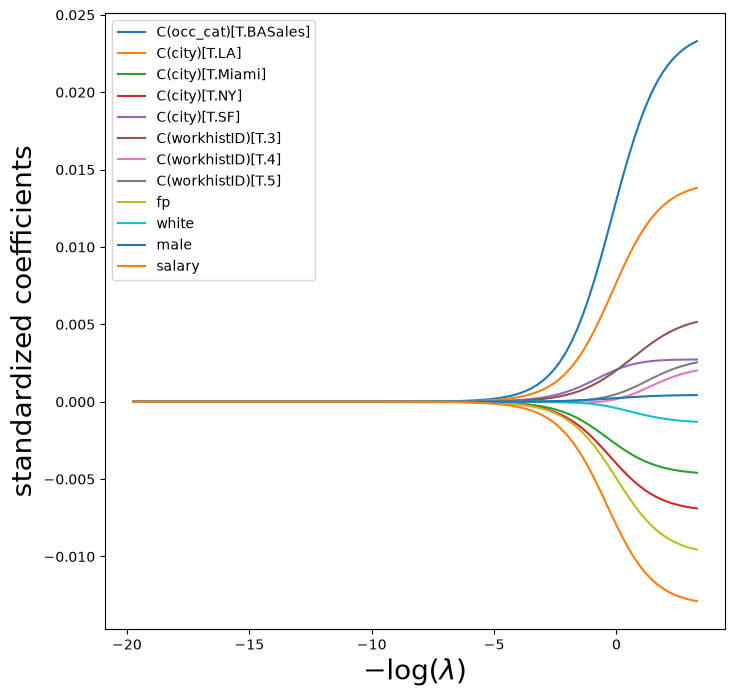

In [12]:
# Build the Ridgecoefficient plot
soln_path = pd.DataFrame(soln_array.T,
                        columns=D.columns,
                        index = -np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'

path_fig, ax = subplots(figsize=(8, 8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('standardized coefficients', fontsize=20)
ax.legend(loc='upper left')

In [13]:
# K fold Cross-Validation
K = 5
kfold = skm.KFold(K,
                  random_state=0,
                  shuffle=True)

In [14]:
# Fit the ridge with CV lambda selection
scaler = StandardScaler(with_mean=True, with_std=True)
ridgeCV = skl.ElasticNetCV(alphas=lambdas,
                            l1_ratio=0.,
                            cv=kfold,
                            tol=1e-7,
                            max_iter=100000)
pipeCV = Pipeline(steps=[('scaler', scaler),
                         ('ridge', ridgeCV)])
pipeCV.fit(X_no_const, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](12,)","[ 0.53, 0.11, 0.31,..., 0.47, 0.5 ,55317.58]"


Text(0, 0.5, 'Mean Squared Error')

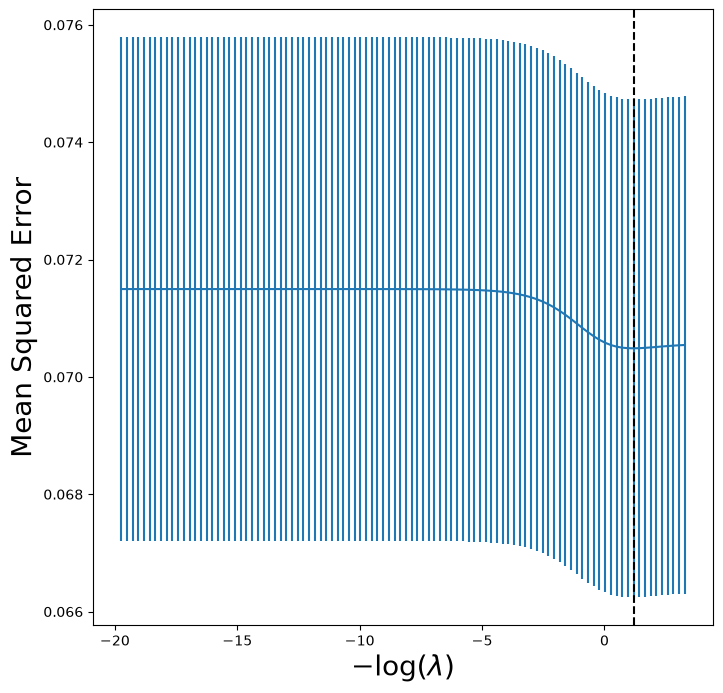

In [15]:
# CV MSE plot, include Error bars
tuned_ridge = pipeCV.named_steps['ridge']
ridgeCV_fig, ax = subplots(figsize=(8, 8))
ax.errorbar(-np.log(lambdas),
            tuned_ridge.mse_path_.mean(axis=1),
            yerr=tuned_ridge.mse_path_.std(axis=1) / np.sqrt(K))
ax.axvline(-np.log(tuned_ridge.alpha_), color='k', linestyle='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Mean Squared Error', fontsize=20)

In [16]:
# Lasso regression model
# Compute the Lasso coefficient
lambdas, soln_array = skl.Lasso.path(Xs, y, l1_ratio=1, n_alphas=100)[:2]

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:637: FutureWarning: 'n_alphas' was deprecated in 1.9 and will be removed in 1.11. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.11. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


Text(0, 0.5, 'standardized coefficient')

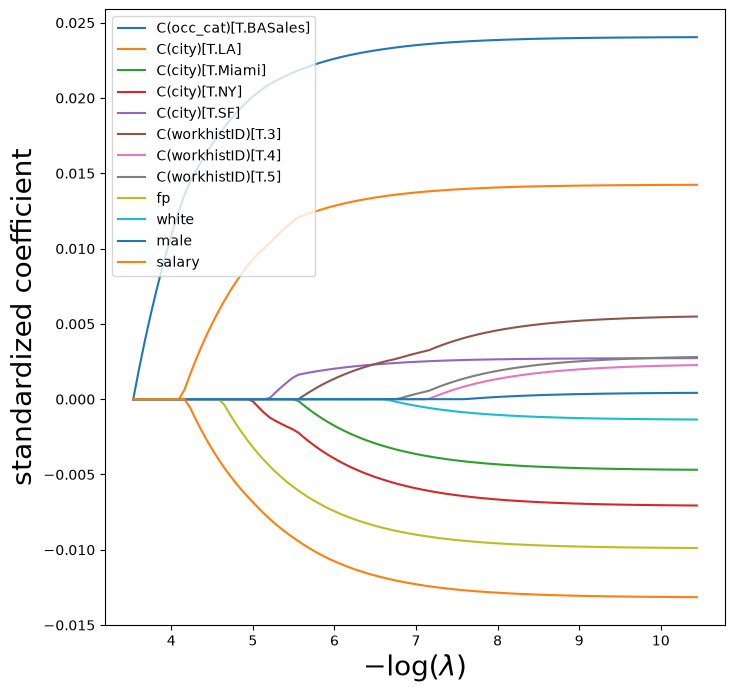

In [17]:
# Build the Lasso coefficient path 
soln_path = pd.DataFrame(soln_array.T,
                        columns=D.columns,
                        index = -np.log(lambdas))
path_fig, ax = subplots(figsize=(8, 8))
soln_path.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('standardized coefficient', fontsize=20)

In [18]:
# Fit the Lasso with CV lambda selection
lassoCV = skl.ElasticNetCV(alphas=100,
                           l1_ratio=1,
                           cv=kfold,
                           tol=1e-7,
                           max_iter=100000)
pipeCV = Pipeline(steps=[('scaler', scaler),
                            ('lasso', lassoCV)])
pipeCV.fit(X_no_const, y)
tuned_lasso = pipeCV.named_steps['lasso']

Text(0, 0.5, 'Mean Squared Error')

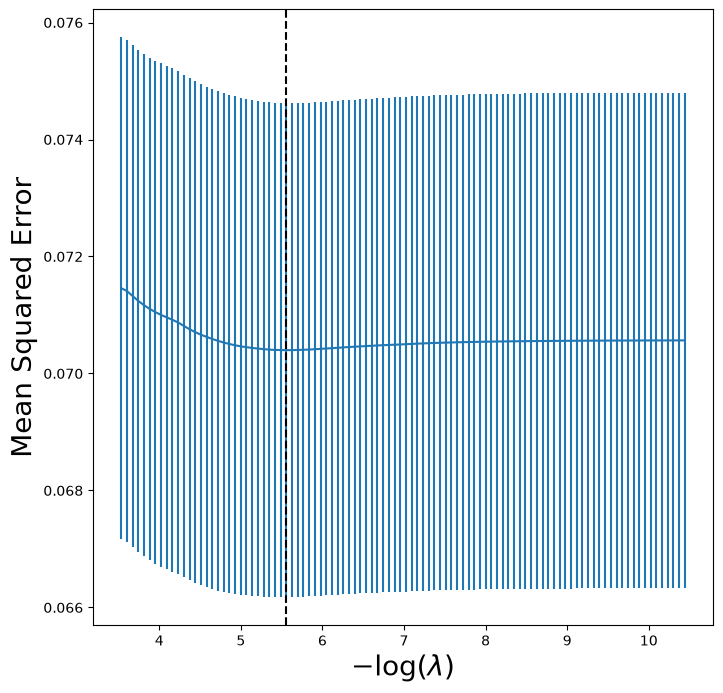

In [19]:
# CV MSE plot, include Error bars
lassoCV_fig, ax = subplots(figsize=(8, 8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(axis=1),
            yerr=tuned_lasso.mse_path_.std(axis=1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), color='k', linestyle='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Mean Squared Error', fontsize=20)    

In [20]:
# Load the Data
from sklearn.tree import (DecisionTreeRegressor as DTR,
                          plot_tree)
from sklearn.ensemble import \
     (RandomForestRegressor as RF,
      GradientBoostingRegressor as GBR)


In [21]:
# Weekly report 4 
# 1. Regression Tree Visualization 
# Visualization
# Split the data into training and test sets
(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(X_no_const,
                                y,
                                test_size=0.3,
                                random_state=0)

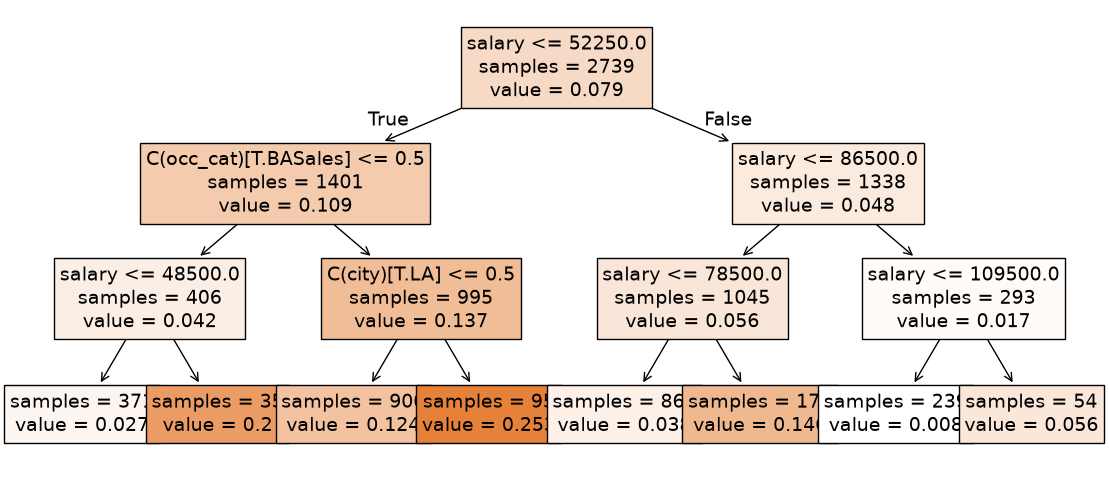

In [22]:
# Fit the regression tree and plot it 
reg = DTR(max_depth=3)
reg.fit(X_train, y_train)
fig, ax = subplots(figsize=(14, 6))
plot_tree(reg, feature_names=list(D.columns), filled =True,
          impurity=False, precision=3, fontsize=14, ax=ax)
fig.savefig('RegressionTree.png', dpi=300, bbox_inches='tight')

In [23]:
from sklearn.tree import export_text
print(export_text(reg, feature_names=list(D.columns), decimals=3))

used = [D.columns[i] for i in reg.tree_.feature if i>=0]
print(pd.Series(used).value_counts())

leaf = reg.tree_.value[reg.tree_.children_left == -1].ravel()
print(leaf.min(), leaf.max())

|--- salary <= 52250.000
|   |--- C(occ_cat)[T.BASales] <= 0.500
|   |   |--- salary <= 48500.000
|   |   |   |--- value: [0.027]
|   |   |--- salary >  48500.000
|   |   |   |--- value: [0.200]
|   |--- C(occ_cat)[T.BASales] >  0.500
|   |   |--- C(city)[T.LA] <= 0.500
|   |   |   |--- value: [0.124]
|   |   |--- C(city)[T.LA] >  0.500
|   |   |   |--- value: [0.253]
|--- salary >  52250.000
|   |--- salary <= 86500.000
|   |   |--- salary <= 78500.000
|   |   |   |--- value: [0.038]
|   |   |--- salary >  78500.000
|   |   |   |--- value: [0.146]
|   |--- salary >  86500.000
|   |   |--- salary <= 109500.000
|   |   |   |--- value: [0.008]
|   |   |--- salary >  109500.000
|   |   |   |--- value: [0.056]

salary                   5
C(occ_cat)[T.BASales]    1
C(city)[T.LA]            1
Name: count, dtype: int64
0.008368200836820083 0.25263157894736843


In [24]:
# Count the number of leaves 
reg.tree_.n_leaves

np.int64(8)

In [25]:
# 2. Random Forest Importance Matrix
#importance Matrix
# Fit the Random Forest 
RF_model = RF(max_features =6,
              random_state=0).fit(X_train, y_train)
y_hat_RF = RF_model.predict(X_test)
np.mean((y_test - y_hat_RF)**2)

np.float64(0.06776659250320302)

In [26]:
# Compute the importance
feature_imp = pd.DataFrame(
    {'importance' : RF_model.feature_importances_},
    index=D.columns)
feature_imp.sort_values(by='importance', ascending=False)

,importance
salary,0.495554
white,0.071522
male,0.070776
fp,0.057043
C(workhistID)[T.5],0.044562
C(workhistID)[T.4],0.043154
C(city)[T.SF],0.042698
C(workhistID)[T.3],0.042497
C(city)[T.Miami],0.037890
C(city)[T.NY],0.034903


In [27]:
# 3. Error Comparison for Bagging, Boosting, Tree, and Random Forest
# Compute the test MSE (Regression Tree)
y_hat_tree = reg.predict(X_test)
np.mean((y_test - y_hat_tree)**2)


np.float64(0.06760176277257363)

In [28]:
# Compute the test RMSE (Regression Tree)
np.sqrt(np.mean((y_test - y_hat_tree)**2))

np.float64(0.26000338992515776)

In [29]:
# Compute the test RMSE (Random Forest)
np.sqrt(np.mean((y_test - y_hat_RF)**2))

np.float64(0.260320173062333)

In [30]:
# Bagging 
# Fit the Bagging model
bag_model = RF(max_features=X_train.shape[1], random_state=0)
bag_model.fit(X_train, y_train)

,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [31]:
# Compute the test MSE (Bagging)
y_hat_bag = bag_model.predict(X_test)
np.mean((y_test - y_hat_bag)**2)

np.float64(0.06483448752113455)

In [32]:
# Compute the test RMSE (Bagging)
np.sqrt(np.mean((y_test - y_hat_bag)**2))

np.float64(0.2546261721055684)

In [33]:
# Boosting 
# Fit the Boosting model 
boost_model = GBR(n_estimators=5000,
                    learning_rate=0.001,
                    max_depth=3,
                    random_state=0)
boost_model.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.001
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",5000
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, i

In [34]:
# Compute the test MSE (Boosting)
y_hat_boost = boost_model.predict(X_test)
np.mean((y_test - y_hat_boost)**2)

np.float64(0.06532666800578035)

In [35]:
# Compute the test RMSE (Boosting)
np.sqrt(np.mean((y_test - y_hat_boost)**2))

np.float64(0.25559082144275125)

In [36]:
import sys 
print(sys.executable)
!{sys.executable} -m pip install graphviz

/opt/anaconda3/bin/python


/Users/jonggillee/Desktop/U of T MA ECON/1st Semester/ECO 1465/Project/Term Project/Weekly Report/Week 5/DAG1.png


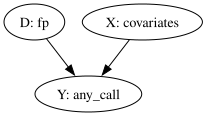

In [37]:
# Weekly report 5
# 1. Two DAGs
# DAG 1
from pathlib import Path 
import graphviz

Path('img').mkdir(exist_ok=True)

out = (Path.home() / 'Desktop' / 'U of T MA ECON' / '1st Semester' / 'ECO 1465'
       / 'Project' / 'Term Project' / 'Weekly Report' / 'Week 5')

graph = graphviz.Digraph(format='png')

nodes = ['D', 'Y', 'X']
labels = ['D: fp', 'Y: any_call', 'X: covariates']

edges = ['DY', 'XY']

[graph.node(n, label=l) for n, l in zip(nodes, labels)]
graph.edges(edges)

graph.render('DAG1', directory=str(out), cleanup=True)
print(out / 'DAG1.png')

graph



/Users/jonggillee/Desktop/U of T MA ECON/1st Semester/ECO 1465/Project/Term Project/Weekly Report/Week 5/DAG2.png


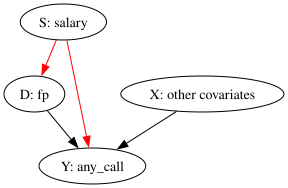

In [38]:
# DAG 2
from pathlib import Path 
import graphviz 

Path('img').mkdir(exist_ok=True)

out = (Path.home() / 'Desktop' / 'U of T MA ECON' / '1st Semester' / 'ECO 1465'
       / 'Project' / 'Term Project' / 'Weekly Report' / 'Week 5')

graph = graphviz.Digraph(format = 'png')

nodes = ['S', 'D', 'Y', 'X']
labels = ['S: salary', 'D: fp', 'Y: any_call', 'X: other covariates']

edges = ['DY', 'XY']

[graph.node(n, label=l) for n, l in zip(nodes, labels)]
graph.edges(edges)

# colour in back door path 
graph.edge('S', 'D', color='#FF0000')
graph.edge('S', 'Y', color='#FF0000')

graph.render('DAG2', directory=str(out), cleanup=True)
print(out / 'DAG2.png')

graph

In [39]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import graphviz

# Make the simulation reproducible and create the image output folder.
np.random.seed(42)
Path('img').mkdir(exist_ok=True)

In [40]:
%pip install dowhy

Note: you may need to restart the kernel to use updated packages.


In [41]:
%pip install --upgrade dowhy

Note: you may need to restart the kernel to use updated packages.


In [42]:
# Weekly report 6
#1. Experimental Benchmark
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# ===== Data preparation (df_reg = the 3,914-row sample from Table 2) =====
dfx = df_reg.copy()
dfx['sales'] = (dfx['occ_cat'] == 'BASales').astype(int)
dummies = pd.get_dummies(dfx[['city', 'workhistID']].astype(str), drop_first=True, dtype=int)
dfx = pd.concat([dfx, dummies], axis=1)
X_cols = ['white', 'male', 'sales'] + list(dummies.columns)

rct = dfx[['fp', 'any_call', 'salary'] + X_cols].dropna().copy()
print('n =', len(rct))   # should be 3914

# ===== 1. Experimental benchmark =====
def ols_coef(df, outcome, regressors, which='fp'):
    X = df[regressors].to_numpy(dtype=float)
    model = LinearRegression().fit(X, df[outcome].to_numpy(dtype=float))
    return model.coef_[regressors.index(which)]

def bootstrap_ci(df, statistic, n_draws=200, seed=1465):
    rng_b = np.random.default_rng(seed)
    draws = []
    for _ in range(n_draws):
        resampled = df.sample(frac=1, replace=True, random_state=int(rng_b.integers(1_000_000_000)))
        draws.append(statistic(resampled))
    return np.percentile(draws, [2.5, 97.5])

def diff_means(df):
    return df.loc[df['fp'] == 1, 'any_call'].mean() - df.loc[df['fp'] == 0, 'any_call'].mean()

def reg_with_covariates(df):
    return ols_coef(df, 'any_call', ['fp', 'salary'] + X_cols)

tau_rct = reg_with_covariates(rct)
print(f'Difference in means (full sample):  {diff_means(rct):.4f}   95% CI {bootstrap_ci(rct, diff_means).round(4)}')
print(f'Regression with covariates (full):  {tau_rct:.4f}   95% CI {bootstrap_ci(rct, reg_with_covariates).round(4)}')

n = 3914
Difference in means (full sample):  -0.0198   95% CI [-0.0378 -0.0064]
Regression with covariates (full):  -0.0198   95% CI [-0.0377 -0.0056]


Recipe B: seed = 1465, alpha = 0.0, gamma = -1.0, selection variable = salary
Full sample:   n = 3914  for-profit = 1956  public = 1958
Biased sample: n = 1916  for-profit = 974  public = 942
        full sample            biased sample           
fp                0          1             0          1
salary    55313.586  55321.574     65574.312  46786.449
white         0.473      0.472         0.465      0.486
male          0.498      0.498         0.519      0.483
sales         0.535      0.535         0.464      0.581
city_NY       0.196      0.195         0.186      0.204


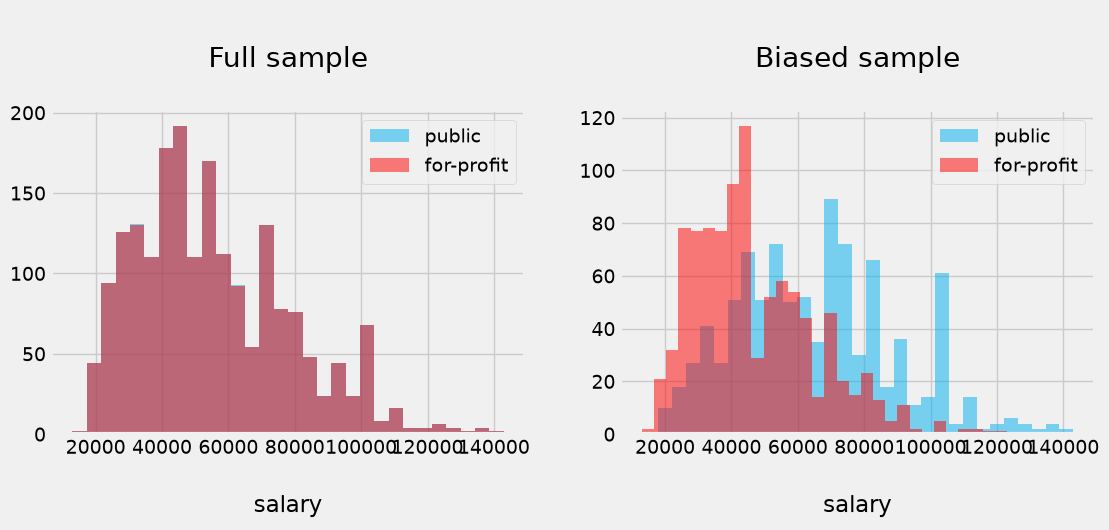

In [43]:
#2. Build the biased sample 
import matplotlib.pyplot as plt

COLORS = ['#00B0F0', '#FF0000']

# ===== 2. Biased sample (Recipe B) =====
seed = 1465
rng = np.random.default_rng(seed)
gamma, alpha = -1.0, 0.0                    # choose your own values and report them

rct['salary_std'] = (rct['salary'] - rct['salary'].mean()) / rct['salary'].std()
sign = np.where(rct['fp'] == 1, 1, -1)      # +gamma for for-profit, -gamma for public
logit = alpha + gamma * sign * rct['salary_std']
p_keep = 1 / (1 + np.exp(-logit))
keep = rng.uniform(size=len(rct)) < p_keep
biased = rct[keep].copy()

print(f'Recipe B: seed = {seed}, alpha = {alpha}, gamma = {gamma}, selection variable = salary')
print('Full sample:   n =', len(rct),    ' for-profit =', int(rct['fp'].sum()),    ' public =', int((rct['fp'] == 0).sum()))
print('Biased sample: n =', len(biased), ' for-profit =', int(biased['fp'].sum()), ' public =', int((biased['fp'] == 0).sum()))

# Balance table: covariate means by credential group
covariates = ['salary', 'white', 'male', 'sales', 'city_NY']
balance = pd.concat({
    'full sample': rct.groupby('fp')[covariates].mean().T,
    'biased sample': biased.groupby('fp')[covariates].mean().T,
}, axis=1).round(3)
print(balance)

# Overlap plot: distribution of salary by credential group
plt.figure(figsize=(12, 4))
plt.subplot(121)
for g, color, label in [(0, COLORS[0], 'public'), (1, COLORS[1], 'for-profit')]:
    plt.hist(rct.loc[rct['fp'] == g, 'salary'], bins=30, alpha=.5, color=color, label=label)
plt.title('\nFull sample\n'); plt.xlabel('\nsalary'); plt.legend()
plt.subplot(122)
for g, color, label in [(0, COLORS[0], 'public'), (1, COLORS[1], 'for-profit')]:
    plt.hist(biased.loc[biased['fp'] == g, 'salary'], bins=30, alpha=.5, color=color, label=label)
plt.title('\nBiased sample\n'); plt.xlabel('\nsalary'); plt.legend()
plt.title('\nBiased sample\n'); plt.xlabel('\nsalary'); plt.legend()
plt.savefig('overlap.pdf', bbox_inches='tight')   # save BEFORE plt.show()
plt.show()

In [44]:
# 3. The naive estimate on the biased sample 
tau_naive = diff_means(biased)                              # difference in means
tau_naive_x = ols_coef(biased, 'any_call', ['fp'] + X_cols) # regression without salary

print(f'Benchmark, full sample (regression):        {tau_rct:.4f}')
print(f'Naive difference in means, biased sample:   {tau_naive:.4f}')
print(f'Regression without salary, biased sample:   {tau_naive_x:.4f}')

Benchmark, full sample (regression):        -0.0198
Naive difference in means, biased sample:   -0.0014
Regression without salary, biased sample:   -0.0068


In [45]:
import sys, dowhy, networkx
print(sys.executable)
print('dowhy:', dowhy.__version__, ' networkx:', networkx.__version__)

/opt/anaconda3/bin/python
dowhy: 0.8  networkx: 3.4.2


In [46]:
%pip install "networkx<3.5" "pandas<3"

Note: you may need to restart the kernel to use updated packages.


In [47]:
# 4. Test DAG 2 with Data (Biased Sample)
import io, warnings
from contextlib import redirect_stdout
from dowhy import CausalModel

warnings.filterwarnings('ignore')    # hide old-version warnings

def make_gml(nodes, edges):
    gml = 'graph [directed 1\n'
    for node in nodes:
        gml += f'\tnode [id "{node}" label "{node}"]\n'
    for source, target in edges:
        gml += f'\tedge [source "{source}" target "{target}"]\n'
    gml += ']'
    return gml

# ===== Step 1: Model the problem (DAG 2) =====
# Arrows: salary -> fp, salary -> any_call, X -> any_call, fp -> any_call
project_nodes = ['fp', 'any_call', 'salary'] + X_cols
project_edges = [('salary', 'fp'), ('salary', 'any_call'), ('fp', 'any_call')] + [(x, 'any_call') for x in X_cols]

biased_dw = biased[project_nodes].copy()
biased_dw['fp'] = biased_dw['fp'].astype(bool)   # DoWhy needs a boolean treatment

model_project = CausalModel(data=biased_dw, treatment='fp', outcome='any_call',
                            graph=make_gml(project_nodes, project_edges))

# ===== Step 2: Identify the estimand =====
estimand_project = model_project.identify_effect(proceed_when_unidentifiable=True)
print(estimand_project)

# ===== Step 3: Obtain the estimate =====
with redirect_stdout(io.StringIO()):             # hide DoWhy's internal prints
    estimate_project = model_project.estimate_effect(
        identified_estimand=estimand_project, method_name='backdoor.linear_regression')
print(f'DoWhy estimate (biased sample):   {estimate_project.value:.4f}')
print(f'Benchmark (RCT):                  {tau_rct:.4f}')
print(f'Naive, regression without salary: {tau_naive_x:.4f}')

# ===== Step 4: Refutation tests =====
with redirect_stdout(io.StringIO()):
    refute_cc = model_project.refute_estimate(
        estimand=estimand_project, estimate=estimate_project,
        method_name='random_common_cause')
print(refute_cc)

with redirect_stdout(io.StringIO()):
    refute_subset = model_project.refute_estimate(
        estimand=estimand_project, estimate=estimate_project,
        method_name='data_subset_refuter', subset_fraction=0.4)
print(refute_subset)

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
  d                      
─────(E[any_call|salary])
d[fp]                    
Estimand assumption 1, Unconfoundedness: If U→{fp} and U→any_call then P(any_call|fp,salary,U) = P(any_call|fp,salary)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!



DoWhy estimate (biased sample):   -0.0137
Benchmark (RCT):                  -0.0198
Naive, regression without salary: -0.0068
Refute: Add a random common cause
Estimated effect:-0.013655425875924707
New effect:-0.013639880980054957
p value:0.8999999999999999

Refute: Use a subset of data
Estimated effect:-0.013655425875924707
New effect:-0.012385592538186028
p value:0.98



In [48]:
# Term project 
# 2. Data and Summary Statistics
# 2.3 Summary Statistics
# Table 1: Descriptive Statistics of the Sample
T = D.copy()
T['anycall'] = y
vars_ = [c for c in T.columns if c !='fp']

table1 = pd.DataFrame({
    'Mean' : T[vars_].mean(),
    'SD' : T[vars_].std(),
    'Public' : T.loc[T['fp']==0, vars_].mean(),
    'For-profit' : T.loc[T['fp']==1, vars_].mean(),
})
table1['Diff'] = table1['For-profit'] - table1['Public']

print(table1.round(3))
table1.to_latex('table1.tex', float_format="%.3f", escape=True)



                            Mean         SD     Public  For-profit   Diff
C(occ_cat)[T.BASales]      0.535      0.499      0.535       0.535  0.000
C(city)[T.LA]              0.105      0.307      0.105       0.105  0.000
C(city)[T.Miami]           0.308      0.462      0.307       0.308  0.000
C(city)[T.NY]              0.195      0.397      0.196       0.195 -0.000
C(city)[T.SF]              0.228      0.420      0.228       0.228  0.000
C(workhistID)[T.3]         0.249      0.433      0.252       0.246 -0.005
C(workhistID)[T.4]         0.251      0.433      0.248       0.254  0.006
C(workhistID)[T.5]         0.249      0.433      0.249       0.249  0.000
white                      0.473      0.499      0.473       0.472 -0.001
male                       0.498      0.500      0.498       0.498 -0.001
salary                 55317.578  23228.502  55313.585   55321.575  7.989
anycall                    0.077      0.267      0.087       0.067 -0.020


diff
-1.0      7
-0.5     52
 0.0    893
 0.5     25
 1.0      1
Name: count, dtype: int64


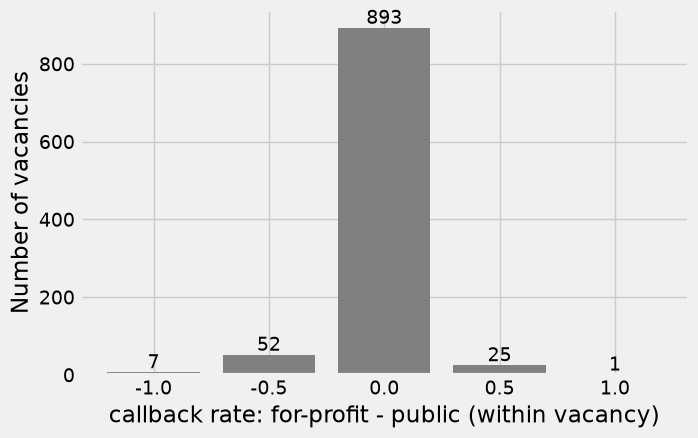

In [49]:
# Figure 1: Histogram
import matplotlib.pyplot as plt
vac = df_reg.groupby(['jobID', 'fp'])['any_call'].mean().unstack().dropna()
vac['diff'] = vac[1] - vac[0]
counts = vac['diff'].round(2).value_counts().reindex([-1.0, -0.5, 0.0, 0.5, 1.0], fill_value=0)
print(counts)

plt.figure(figsize=(7, 4.5))
plt.bar(counts.index.astype(str), counts.values, color='gray')
for i, v in enumerate(counts.values):
    plt.text(i, v + 10, str(v), ha='center')
plt.xlabel('callback rate: for-profit - public (within vacancy)')
plt.ylabel('Number of vacancies')
plt.savefig('figure1.pdf', dpi=300, bbox_inches='tight')
plt.show()

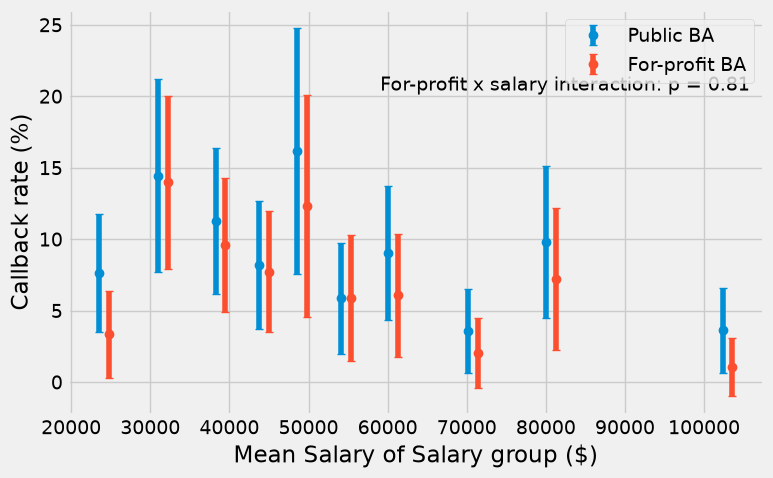

In [50]:
# Figure 2: Scatter Plot
cl = dict(cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})
df_reg['sal_group'] = pd.qcut(df_reg['salary'], 10, labels=False)

rate = df_reg.groupby(['sal_group', 'fp'])['any_call'].mean().unstack() *100
vac = df_reg.groupby(['sal_group', 'fp', 'jobID'])['any_call'].mean()
se = vac.groupby(['sal_group', 'fp']).sem().unstack() * 100 
sal = df_reg.groupby('sal_group')['salary'].mean()

plt.figure(figsize=(8, 5))
plt.errorbar(sal - 600, rate[0], yerr=1.96*se[0], fmt='o', capsize=3, label='Public BA')
plt.errorbar(sal + 600, rate[1], yerr=1.96*se[1], fmt='o', capsize=3, label='For-profit BA')
plt.xlabel('Mean Salary of Salary group ($)')
plt.ylabel('Callback rate (%)')
plt.legend()
df_reg['salary10k'] = df_reg['salary'] / 10000
p = smf.ols(model_formula + ' + fp:salary10k', data=df_reg).fit(**cl).pvalues['fp:salary10k']
plt.text(0.98, 0.80, f'For-profit x salary interaction: p = {p:.2f}', transform=plt.gca().transAxes, ha='right')
plt.savefig('figure2.pdf', dpi = 300, bbox_inches='tight')
plt.show()

fp           0      1    gap     n     lon    lat
city                                             
Chicago  0.087  0.056 -3.098   641  -87.63  41.88
LA       0.150  0.102 -4.854   412 -118.24  34.05
Miami    0.071  0.063 -0.831  1204  -80.19  25.76
NY       0.063  0.055 -0.769   765  -74.01  40.71
SF       0.101  0.076 -2.466   892 -122.42  37.77


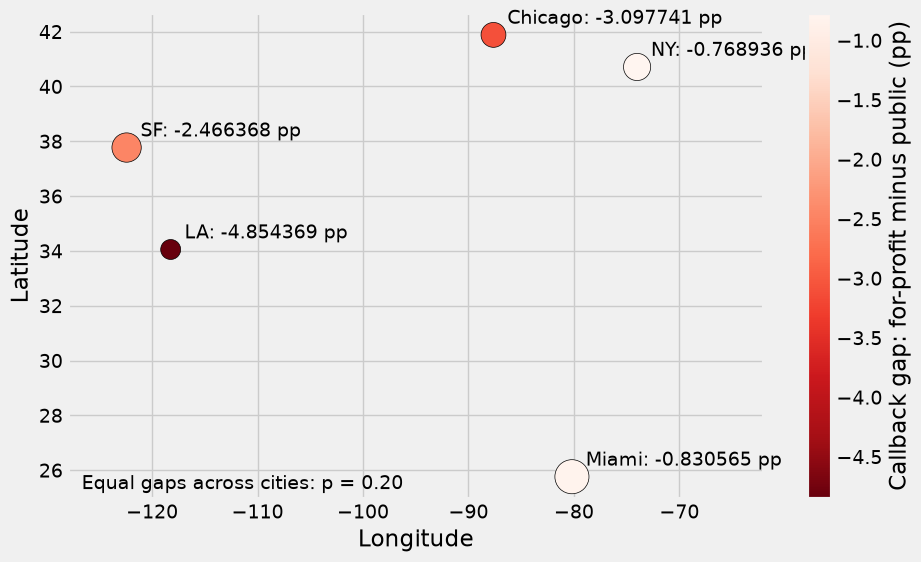

In [51]:
# MAP
by_city = df_reg.pivot_table(index='city', columns='fp', values='any_call', aggfunc='mean')
by_city['gap'] = (by_city[1] - by_city[0]) * 100 
by_city['n'] = df_reg.groupby('city').size()

coords = {'Chicago': (-87.63, 41.88), 'LA': (-118.24, 34.05), 'Miami': (-80.19, 25.76),
          'NY': (-74.01, 40.71), 'SF': (-122.42, 37.77)}
by_city['lon'] = [coords[c][0] for c in by_city.index]
by_city['lat'] = [coords[c][1] for c in by_city.index]
print(by_city.round(3))

plt.figure(figsize=(10, 6))
plt.scatter(by_city['lon'], by_city['lat'], s=by_city['n']*0.5,
            c=by_city['gap'], cmap='Reds_r', edgecolor='k')
for city, r in by_city.iterrows():
    plt.annotate(f"{city}: {r['gap']: 1f} pp", (r['lon'], r['lat']),
                 xytext=(10,8), textcoords='offset points')
plt.xlim(-128, -62)
plt.colorbar(label='Callback gap: for-profit minus public (pp)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
res = smf.ols(model_formula + ' + fp:C(city)', data=df_reg).fit(**cl)
R = np.eye(len(res.params))[res.params.index.str.startswith('fp:')]
p = float(res.wald_test(R, scalar=True).pvalue)
plt.text(0.02, 0.02, f'Equal gaps across cities: p = {p:.2f}', transform=plt.gca().transAxes)
plt.savefig('figure3.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [52]:
# 3.4 Causal Regression
import statsmodels.formula.api as smf

# (1) Vacancy fixed effects, vacancy-clustered SE
fe = smf.ols('any_call ~ fp + C(jobID)', data=df_reg).fit(
    cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})
print(fe.params['fp'], fe.bse['fp'], fe.rsquared, int(fe.nobs))

# (2)-(4) Heterogeneity: interaction + controls, Wald test of interactions
base = 'any_call ~ fp + white + male + salary + C(occ_cat) + C(city) + C(workhistID)'
df_reg = df_reg.copy()
df_reg['sal10k'] = df_reg['salary'] / 10000
specs = {
 'salary': 'any_call ~ fp*sal10k + white + male + C(occ_cat) + C(city) + C(workhistID)',
 'sales' : base + ' + fp:C(occ_cat)',
 'city'  : base + ' + fp:C(city)',
}
for k, f in specs.items():
    m = smf.ols(f, data=df_reg).fit(cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})
    names = [n for n in m.params.index if n.startswith('fp:') or n.endswith(':fp')]
    print(k, m.wald_test(' , '.join(f'{n} = 0' for n in names), scalar=True).pvalue)


-0.01993865030674778 0.006124130056245788 0.6982179292712698 3914
salary 0.8120085475758979
sales 0.44875268823972436
city 0.19857131593350244


In [53]:
for k, f in specs.items():
    m = smf.ols(f, data=df_reg).fit(cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})
    print(k, round(m.rsquared, 3))
    print(m.params.filter(like='fp').round(4))
    print(m.bse.filter(like='fp').round(4))

salary 0.02
fp          -0.0171
fp:sal10k   -0.0005
dtype: float64
fp           0.0142
fp:sal10k    0.0021
dtype: float64
sales 0.02
fp                         -0.0156
fp:C(occ_cat)[T.BASales]   -0.0078
dtype: float64
fp                          0.0056
fp:C(occ_cat)[T.BASales]    0.0103
dtype: float64
city 0.021
fp                    -0.0308
fp:C(city)[T.LA]      -0.0171
fp:C(city)[T.Miami]    0.0226
fp:C(city)[T.NY]       0.0228
fp:C(city)[T.SF]       0.0062
dtype: float64
fp                     0.0113
fp:C(city)[T.LA]       0.0230
fp:C(city)[T.Miami]    0.0140
fp:C(city)[T.NY]       0.0156
fp:C(city)[T.SF]       0.0174
dtype: float64


In [54]:
#3.5 Ridge and Lasso 
# I used the Ridge and Lasso figure that i made during the weekly report.

In [55]:
#3.6 Robustness Check 
from pathlib import Path
import pandas as pd
from scipy.stats import norm
import statsmodels.formula.api as smf

ROOT = Path.cwd()
raw = pd.read_stata(ROOT / 'DYAGK_audit_data.dta')
d = raw.loc[(raw['ba'] == 1) & (raw['jobID'] != 593)].dropna(subset=['salary']).copy()
formula = 'any_call ~ fp + white + male + salary + C(occ_cat) + C(city) + C(workhistID)'

results = {}
ols = smf.ols(formula, data=d).fit(cov_type='cluster', cov_kwds={'groups': d['jobID']})
results['OLS'] = (ols.params['fp'], ols.bse['fp'], int(ols.nobs))

for label, method in [('Logit', smf.logit), ('Probit', smf.probit)]:
    fitted = method(formula, data=d).fit(disp=False, cov_type='cluster', cov_kwds={'groups': d['jobID']})
    margins = fitted.get_margeff(at='overall', method='dydx', dummy=True).summary_frame()
    results[label] = (margins.loc['fp', 'dy/dx'], margins.loc['fp', 'Std. Err.'], int(fitted.nobs))

def star(p):
    return '$^{***}$' if p < .01 else '$^{**}$' if p < .05 else '$^{*}$' if p < .10 else ''

rows = []
for label in ['OLS', 'Logit', 'Probit']:
    effect, se, n = results[label]
    p = norm.cdf(effect / se)  # H1: effect < 0
    rows.append({'Model': label, 'Effect': 100 * effect, 'SE': 100 * se, 'p': p, 'N': n})
out = pd.DataFrame(rows).set_index('Model')

coeff = [f"{out.loc[k,'Effect']:.2f}{star(out.loc[k,'p'])}" for k in out.index]
ses = [f"({out.loc[k,'SE']:.2f})" for k in out.index]
ps = [f"{out.loc[k,'p']:.4f}" for k in out.index]
ns = [f"{int(out.loc[k,'N']):,}" for k in out.index]

lines = [
    r'\begin{table}[htbp]',
    r'\centering',
    r'\caption{Robustness Checks Using Logit and Probit}',
    r'\label{tab:robust}',
    r'\small',
    r'\begin{tabular}{lccc}',
    r'\toprule',
    r' & (1) OLS & (2) Logit & (3) Probit \\',
    r'\midrule',
    'For-profit effect (pp) & ' + ' & '.join(coeff) + r' \\',
    'Clustered SE (pp) & ' + ' & '.join(ses) + r' \\',
    'One-sided $p$-value & ' + ' & '.join(ps) + r' \\',
    r'\midrule',
    r'Controls & Yes & Yes & Yes \\',
    'Observations & ' + ' & '.join(ns) + r' \\',
    r'\bottomrule',
    r'\end{tabular}',
    r'\vspace{2mm}',
    r'\begin{minipage}{0.95\textwidth}',
    r'\footnotesize\textit{Notes:} OLS reports the linear probability model coefficient; Logit and Probit report average marginal effects (AME), the average discrete change in predicted callback probability when the for-profit indicator changes from 0 to 1. Effects and standard errors are in percentage points. All specifications include the same 11 controls as Table 2, Column (3). Standard errors are clustered at the vacancy level. One-sided $p$-values test $H_1:\beta<0$ using asymptotic normal inference. $^{*}p<0.10$, $^{**}p<0.05$, $^{***}p<0.01$ (one-sided).',
    r'\end{minipage}',
    r'\end{table}',
]
(ROOT / 'table6_robustness.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')
print(out.round(4))

        Effect      SE       p     N
Model                               
OLS    -1.9821  0.5300  0.0001  3914
Logit  -1.9663  0.5300  0.0001  3914
Probit -1.9765  0.5221  0.0001  3914


In [56]:
#3.8 DAG
cols = ['white', 'male', 'salary', 'occ_cat', 'city', 'fp', 'workhistID']
variation = df_reg.groupby('jobID')[cols].nunique().max()
print(variation)

white         1
male          1
salary        1
occ_cat       1
city          1
fp            2
workhistID    4
dtype: int64


In [57]:
# Appendix 
# Section 3.4 Causal Regression Table 5 
# salary interaction, occupation(sales) interaction, city interaction. 
for k, f in specs.items():
    m = smf.ols(f, data=df_reg).fit(cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})
    out = pd.DataFrame({'coef': m.params.round(4), 'se': m.bse.round(4)})
    print('===', k, '===')
    print(m.params.round(4))
    print(m.bse.round(4))

=== salary ===
Intercept                0.0864
C(occ_cat)[T.BASales]    0.0482
C(city)[T.LA]            0.0464
C(city)[T.Miami]        -0.0102
C(city)[T.NY]           -0.0179
C(city)[T.SF]            0.0065
C(workhistID)[T.3]       0.0129
C(workhistID)[T.4]       0.0055
C(workhistID)[T.5]       0.0067
fp                      -0.0171
sal10k                  -0.0054
fp:sal10k               -0.0005
white                   -0.0028
male                     0.0009
dtype: float64
Intercept                0.0289
C(occ_cat)[T.BASales]    0.0135
C(city)[T.LA]            0.0323
C(city)[T.Miami]         0.0221
C(city)[T.NY]            0.0228
C(city)[T.SF]            0.0241
C(workhistID)[T.3]       0.0079
C(workhistID)[T.4]       0.0075
C(workhistID)[T.5]       0.0078
fp                       0.0142
sal10k                   0.0029
fp:sal10k                0.0021
white                    0.0140
male                     0.0141
dtype: float64
=== sales ===
Intercept                   0.0858
C(occ_cat)

In [ ]:
# Appendix 
# Section 3.3.1 
# To reinforce, the sentence "Vacancy-level characteristics are mechanically balanced by design so the work-history variables provide a more informative check of randomization."

cl= dict(cov_type='cluster', cov_kwds={'groups': df_reg['jobID']})

for wh in [3, 4, 5]:
    df_reg[f'wh{wh}'] = (df_reg['workhistID'] == wh).astype(int)
    m = smf.ols(f'wh{wh} ~ fp', data=df_reg).fit(**cl)
    pub_mean = df_reg.loc[df_reg['fp'] ==0, f'wh{wh}'].mean()
    print(f"WH{wh}: mean={pub_mean:.4f} diff={m.params['fp']:.4f} "
          f"se={m.bse['fp']:.4f} p={m.pvalues['fp']:.4f}")

joint_model = smf.ols('fp ~ wh3 + wh4 + wh5', data=df_reg).fit(**cl)
f_test = joint_model.f_test('wh3=0, wh4=0, wh5=0')
print(f_test)

WH3: mean=0.2518 diff=-0.0054 se=0.0160 p=0.7368
WH4: mean=0.2477 diff=0.0059 se=0.0160 p=0.7132
WH5: mean=0.2492 diff=0.0003 se=0.0160 p=0.9873
<F test: F=0.06312692106923391, p=0.979272747130015, df_denom=979, df_num=3>
